# LoRA vs LoRA+ Experimental Evaluation
## GPT-2 + GLUE Quora Question Pairs (QQP)

### Project Overview

This experiment compares standard LoRA and LoRA+ for
parameter-efficient fine-tuning of GPT-2 on QQP.

**Experimental Setup**
- Model: GPT-2
- Dataset: GLUE QQP
- Training subset: 50,000 examples
- Validation: Full QQP validation split
- Training epochs: 3
- Screening: 9 hyperparameter configurations
- Final evaluation: 2 selected methods × 3 seeds
- Seeds: 42, 43, 44

**Reproducibility**
All experiment results are persisted in Google Drive.
Completed runs are reused rather than retrained.

## 1. Project Setup and GitHub Integration

This notebook uses the shared LoRA-Plus GitHub repository
for version control and reproducibility.

Repository:
https://github.com/Ramprasath-Meganathan/LoRA-Plus

Experiment: GPT-2 + GLUE QQP

Training outputs are stored persistently in Google Drive.
GitHub is used for notebook code and lightweight results.

In [15]:
from pathlib import Path
import subprocess
import sys
import os

REPO_URL = "https://github.com/Ramprasath-Meganathan/LoRA-Plus.git"
PROJECT_DIR = Path("/content/LoRA-Plus")

# Clone only if the repository isn't already available
if not (PROJECT_DIR / ".git").is_dir():
    if PROJECT_DIR.exists():
        raise RuntimeError(
            "Directory exists but is not a Git repository. "
            "Choose another clone location."
        )

    subprocess.run(
        ["git", "clone", REPO_URL, str(PROJECT_DIR)],
        check=True
    )

print("Repository:", PROJECT_DIR)

# Make shared project modules importable
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("GitHub project setup complete.")

Repository: /content/LoRA-Plus
GitHub project setup complete.


## 2. Install Required Dependencies

Install the required libraries from the repository's `requirements.txt` file for model fine-tuning, LoRA/LoRA+ optimization, dataset processing, and evaluation.

Remove incompatible `torchao` installations to ensure compatibility with PEFT in Google Colab.

In [16]:
%pip -q install "transformers==4.57.1" "peft==0.17.1" "datasets==3.6.0" "accelerate==1.10.1" "scikit-learn>=1.4,<2" "pandas>=2,<3" "matplotlib>=3.8,<4"
%pip uninstall -y torchao

In [18]:
import os, json, gc, time, random, hashlib, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.metrics import accuracy_score, f1_score
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, TrainingArguments, Trainer,
                          get_linear_schedule_with_warmup, set_seed)
from peft import LoraConfig, TaskType, get_peft_model
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

ROOT = Path('/content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k')
ROOT.mkdir(parents=True, exist_ok=True)

print("Results saved to:", ROOT)

ROOT.mkdir(parents=True, exist_ok=True)
print('Output directory:', ROOT)
print('CUDA:', torch.cuda.is_available(), 'GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')
assert torch.cuda.is_available(), 'Use Runtime > Change runtime type > GPU before training.'

CFG = dict(model_name='gpt2', dataset='qqp', subset_seed=42, train_samples=50_000,
           max_length=128, rank=8, lora_alpha=8, lora_dropout=0.1,
           target_modules=['c_attn','c_proj','c_fc'], epochs=3,
           train_batch_size=8, eval_batch_size=32, gradient_accumulation_steps=4,
           adam_beta1=0.9, adam_beta2=0.99, adam_epsilon=1e-8,
           weight_decay=0.01, warmup_steps=0, final_seeds=[42,43,44])
# Physical batch 8 x accumulation 4 = effective batch 32 on Colab T4.
# Classification head LR=LR_A is a documented implementation choice.
(ROOT/'config.json').write_text(json.dumps(CFG,indent=2))
print(json.dumps(CFG,indent=2))

Mounted at /content/drive
Results saved to: /content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k
Output directory: /content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k
CUDA: True GPU: NVIDIA L4
{
  "model_name": "gpt2",
  "dataset": "qqp",
  "subset_seed": 42,
  "train_samples": 50000,
  "max_length": 128,
  "rank": 8,
  "lora_alpha": 8,
  "lora_dropout": 0.1,
  "target_modules": [
    "c_attn",
    "c_proj",
    "c_fc"
  ],
  "epochs": 3,
  "train_batch_size": 8,
  "eval_batch_size": 32,
  "gradient_accumulation_steps": 4,
  "adam_beta1": 0.9,
  "adam_beta2": 0.99,
  "adam_epsilon": 1e-08,
  "weight_decay": 0.01,
  "warmup_steps": 0,
  "final_seeds": [
    42,
    43,
    44
  ]
}


## 3. Experiment Configuration and GPU Verification

Select RoBERTa-base and the Quora Question Pairs (QQP) dataset.

The experiment uses three training epochs, nine hyperparameter screening configurations, and three random seeds (42, 43, 44) for final evaluation.

Verify that a GPU is available before starting training.

In [19]:
import torch

MODEL_NAME = "roberta"
DATASET_NAME = "qqp"

assert torch.cuda.is_available(), (
    "GPU unavailable. Enable a GPU runtime in Colab."
)

print("Model:", MODEL_NAME)
print("Dataset:", DATASET_NAME)
print("GPU:", torch.cuda.get_device_name(0))

Model: roberta
Dataset: qqp
GPU: NVIDIA L4


## 4. Load the fixed 50k QQP training subset and full validation split

In [20]:
raw = load_dataset('nyu-mll/glue', 'qqp')
train_raw = raw['train'].shuffle(seed=CFG['subset_seed']).select(range(CFG['train_samples']))
valid_raw = raw['validation']
assert len(train_raw)==50_000 and len(valid_raw)==40_430
# Save a fingerprint of the selected dataset so experiments can be audited.
subset_keys = [str(x) for x in train_raw['idx']]
subset_digest = hashlib.sha256(','.join(subset_keys).encode()).hexdigest()
(ROOT/'subset_sha256.txt').write_text(subset_digest+'\n')
print('Train:',len(train_raw),'Validation:',len(valid_raw),'Subset SHA256:',subset_digest)
print(train_raw[0])

Train: 50000 Validation: 40430 Subset SHA256: 4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01
{'question1': 'What would Rhaegar and Jon have thought of each other?', 'question2': 'What is the amount of torque a 2000 Jeep Cherokee can output?', 'label': 0, 'idx': 260796}


## 5. GPT-2 tokenization (same for every run)

In [21]:
tokenizer = AutoTokenizer.from_pretrained(CFG['model_name'])
tokenizer.pad_token = tokenizer.eos_token

def tokenize_qqp(batch):
    # This pair format is a documented project choice, not confirmed authors' format.
    text = [f'Question 1: {a}\nQuestion 2: {b}'
            for a,b in zip(batch['question1'],batch['question2'])]
    return tokenizer(text, truncation=True, max_length=CFG['max_length'], padding=False)

train_ds = train_raw.map(tokenize_qqp, batched=True,
                         remove_columns=['question1','question2','idx'], desc='Tokenize train')
valid_ds = valid_raw.map(tokenize_qqp, batched=True,
                         remove_columns=['question1','question2','idx'], desc='Tokenize validation')
collator = DataCollatorWithPadding(tokenizer=tokenizer)
assert 'label' in train_ds.column_names
print('Train columns:',train_ds.column_names)
print('Sample token length:',len(train_ds[0]['input_ids']))

Tokenize train:   0%|          | 0/50000 [00:00<?, ? examples/s]

Tokenize validation:   0%|          | 0/40430 [00:00<?, ? examples/s]

Train columns: ['label', 'input_ids', 'attention_mask']
Sample token length: 34


## 6. Fresh model, optimizer, metrics, and experiment runner

In [22]:
def fresh_model(seed):
    set_seed(seed)
    base = AutoModelForSequenceClassification.from_pretrained(
        CFG['model_name'], num_labels=2, pad_token_id=tokenizer.pad_token_id)
    adapter = LoraConfig(task_type=TaskType.SEQ_CLS,
        r=CFG['rank'], lora_alpha=CFG['lora_alpha'], lora_dropout=CFG['lora_dropout'],
        target_modules=CFG['target_modules'], fan_in_fan_out=True,
        modules_to_save=['score'], bias='none', init_lora_weights=True)
    model = get_peft_model(base, adapter)
    return model

def make_optimizer(model, lr_A, lr_B):
    groups = {'A':[], 'B':[], 'head':[]}
    for name, p in model.named_parameters():
        if not p.requires_grad: continue
        if 'lora_A' in name: groups['A'].append(p)
        elif 'lora_B' in name: groups['B'].append(p)
        else: groups['head'].append(p)
    assert groups['A'] and groups['B'] and groups['head'], 'Missing trainable parameter group'
    return torch.optim.AdamW([
        {'params':groups['A'],'lr':lr_A},
        {'params':groups['B'],'lr':lr_B},
        {'params':groups['head'],'lr':lr_A},
    ], betas=(CFG['adam_beta1'],CFG['adam_beta2']),
       eps=CFG['adam_epsilon'], weight_decay=CFG['weight_decay'])

def metrics_fn(pred):
    logits, labels = pred
    predicted = np.argmax(logits,axis=-1)
    return {'accuracy':float(accuracy_score(labels,predicted)),
            'f1':float(f1_score(labels,predicted,zero_division=0)),
            'macro_f1':float(f1_score(labels,predicted,average='macro',zero_division=0))}

def run_experiment(lr_A, ratio, seed, stage, train_data=None, valid_data=None,
                   epochs=None, save_adapter=False):
    lr_B = lr_A * ratio
    train_data = train_ds if train_data is None else train_data
    valid_data = valid_ds if valid_data is None else valid_data
    epochs = CFG['epochs'] if epochs is None else epochs
    run_id = f'{stage}_A{lr_A:.0e}_ratio{ratio}_seed{seed}'
    out = ROOT / stage / run_id
    out.mkdir(parents=True,exist_ok=True)
    result_file = out/'result.json'
    if result_file.exists():
        print('SKIPPING completed run:',run_id)
        return json.loads(result_file.read_text())
    model = fresh_model(seed)
    optimizer = make_optimizer(model,lr_A,lr_B)
    total_steps = int(np.ceil(len(train_data)/(CFG['train_batch_size'] * CFG['gradient_accumulation_steps'])) * epochs)
    scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps)
    args = TrainingArguments(
        output_dir=str(out), num_train_epochs=epochs,
        per_device_train_batch_size=CFG['train_batch_size'],
        per_device_eval_batch_size=CFG['eval_batch_size'],
        gradient_accumulation_steps=CFG['gradient_accumulation_steps'],
        eval_strategy='steps', eval_steps=200,
        save_strategy='steps',save_steps=1000,save_total_limit=2,
        logging_strategy='steps',logging_steps=100,
        report_to='none',fp16=torch.cuda.is_available(),
        seed=seed,data_seed=seed, remove_unused_columns=True,
        dataloader_num_workers=0)
    trainer = Trainer(model=model,args=args,train_dataset=train_data,
                      eval_dataset=valid_data,processing_class=tokenizer,
                      data_collator=collator,compute_metrics=metrics_fn,
                      optimizers=(optimizer,scheduler))
    torch.cuda.reset_peak_memory_stats()
    started=time.perf_counter()
    from transformers.trainer_utils import get_last_checkpoint
    last_checkpoint = get_last_checkpoint(str(out))
    trained=trainer.train(resume_from_checkpoint=last_checkpoint) if last_checkpoint else trainer.train()
    measured=trainer.evaluate()
    elapsed=time.perf_counter()-started
    result = dict(stage=stage,run_id=run_id,seed=int(seed),lr_A=float(lr_A),
        lr_B=float(lr_B),ratio=int(ratio),method='LoRA' if ratio==1 else 'LoRA+',
        train_samples=len(train_data),validation_samples=len(valid_data),epochs=float(epochs),
        accuracy=float(measured['eval_accuracy']),f1=float(measured['eval_f1']),
        macro_f1=float(measured['eval_macro_f1']),
        eval_loss=float(measured['eval_loss']),train_runtime_seconds=float(trained.metrics['train_runtime']),
        total_runtime_seconds=float(elapsed),
        peak_gpu_memory_gb=float(torch.cuda.max_memory_allocated()/1024**3),
        trainable_parameters=int(sum(p.numel() for p in model.parameters() if p.requires_grad)),
        global_steps=int(trainer.state.global_step),subset_sha256=subset_digest)
    # Store convergence history even if the Colab session later disconnects.
    (out/'trainer_log_history.json').write_text(json.dumps(trainer.state.log_history,indent=2))
    if save_adapter:
        trainer.save_model(str(out/'adapter'))
        tokenizer.save_pretrained(str(out/'adapter'))
    result_file.write_text(json.dumps(result,indent=2))
    print(json.dumps(result,indent=2))
    del trainer, model, optimizer, scheduler
    gc.collect()
    torch.cuda.empty_cache()
    return result

SANITY TEST

In [23]:
from tempfile import TemporaryDirectory

import numpy as np
import torch
from datasets import load_dataset
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, f1_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
    set_seed,
)

assert torch.cuda.is_available(), "Enable a GPU in Colab under Runtime → Change runtime type."
set_seed(42)

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token
qqp = load_dataset("nyu-mll/glue", "qqp")

def tokenize_pairs(batch):
    texts = [
        f"Question 1: {q1}\nQuestion 2: {q2}"
        for q1, q2 in zip(batch["question1"], batch["question2"])
    ]
    return tokenizer(texts, truncation=True, max_length=128)

train_data = qqp["train"].shuffle(seed=42).select(range(2_048)).map(
    tokenize_pairs, batched=True, remove_columns=["question1", "question2", "idx"]
)
validation_data = qqp["validation"].shuffle(seed=42).select(range(512)).map(
    tokenize_pairs, batched=True, remove_columns=["question1", "question2", "idx"]
)

base_model = AutoModelForSequenceClassification.from_pretrained(
    "gpt2", num_labels=2, pad_token_id=tokenizer.pad_token_id
)
model = get_peft_model(
    base_model,
    LoraConfig(
        task_type=TaskType.SEQ_CLS,
        r=8,
        lora_alpha=8,
        lora_dropout=0.1,
        target_modules=["c_attn", "c_proj", "c_fc"],
        fan_in_fan_out=True,
        modules_to_save=["score"],
        bias="none",
    ),
)

groups = {"A": [], "B": [], "head": []}
for name, parameter in model.named_parameters():
    if parameter.requires_grad:
        if "lora_A" in name:
            groups["A"].append(parameter)
        elif "lora_B" in name:
            groups["B"].append(parameter)
        else:
            groups["head"].append(parameter)

assert all(groups.values()), "Expected LoRA A, LoRA B, and classifier parameters."
optimizer = torch.optim.AdamW(
    [
        {"params": groups["A"], "lr": 1e-4},
        {"params": groups["B"], "lr": 4e-4},
        {"params": groups["head"], "lr": 1e-4},
    ],
    betas=(0.9, 0.99),
    eps=1e-8,
    weight_decay=0.01,
)

def compute_metrics(prediction):
    predicted = np.argmax(prediction.predictions, axis=-1)
    return {
        "accuracy": accuracy_score(prediction.label_ids, predicted),
        "f1": f1_score(prediction.label_ids, predicted, zero_division=0),
    }

with TemporaryDirectory(prefix="gpt2_qqp_sanity_") as output_dir:
    trainer = Trainer(
        model=model,
        args=TrainingArguments(
            output_dir=output_dir,
            max_steps=50,
            per_device_train_batch_size=8,
            per_device_eval_batch_size=32,
            gradient_accumulation_steps=4,
            logging_steps=10,
            save_strategy="no",
            report_to="none",
            fp16=True,
            seed=42,
            data_seed=42,
        ),
        train_dataset=train_data,
        eval_dataset=validation_data,
        processing_class=tokenizer,
        data_collator=DataCollatorWithPadding(tokenizer),
        optimizers=(optimizer, None),
        compute_metrics=compute_metrics,
    )
    trainer.train()
    steps = trainer.state.global_step
    assert steps == 50, f"Expected 50 optimizer steps, got {steps}."
    metrics = trainer.evaluate()

print(f"Sanity test passed after {steps} optimizer steps.")
print(f"Validation accuracy: {metrics['eval_accuracy']:.4f}")
print(f"Validation binary F1: {metrics['eval_f1']:.4f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Step,Training Loss
10,13.676917
20,8.732017
30,5.657051
40,4.672172
50,3.467508


Training Loss,Validation Loss,Step,Accuracy,F1
3.467508,0.955286,50,0.580078,0.494118


Sanity test passed after 50 optimizer steps.
Validation accuracy: 0.5801
Validation binary F1: 0.4941


## 7. Screening - nine independent cells

Run each cell separately, in order or at your convenience. Each run trains for **3 epochs** on the **same 50,000 QQP examples** using **seed 42**. Each saves its own checkpoints and results to Drive. Previously completed runs are skipped automatically. **Do not use Run all** unless you want all nine to execute sequentially.


In [59]:
SCREENING = [
    {'lr_A':0.0001, 'ratio':1},
    {'lr_A':0.0002, 'ratio':1},
    {'lr_A':0.0004, 'ratio':1},
    {'lr_A':0.0001, 'ratio':4},
    {'lr_A':0.0001, 'ratio':8},
    {'lr_A':0.0001, 'ratio':16},
    {'lr_A':0.0002, 'ratio':4},
    {'lr_A':0.0002, 'ratio':8},
    {'lr_A':0.0002, 'ratio':16},
]
assert len(SCREENING) == 9
print("Nine screening settings ready. Run the individual experiment cells below.")


Nine screening settings ready. Run the individual experiment cells below.


### Screening 1/9 - LoRA | λ = 1

LR A = `0.0001` · LR B = `0.0001` · 3 epochs · seed 42


In [ ]:
result_screen_1 = run_experiment(lr_A=0.0001, ratio=1, seed=42, stage='screening')


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.675800,0.603404,0.686198,0.603915,0.672045
400,0.570400,0.506904,0.735098,0.615467,0.706711


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.675800,0.603404,0.686198,0.603915,0.672045
400,0.570400,0.506904,0.735098,0.615467,0.706711
600,0.520300,0.472408,0.756814,0.687754,0.744306
800,0.496300,0.455062,0.770245,0.707313,0.759108
1000,0.478400,0.443801,0.779050,0.727012,0.770719
1200,0.459000,0.436413,0.786545,0.705239,0.768967
1400,0.462500,0.423931,0.791145,0.734916,0.781305
1600,0.453500,0.421619,0.794657,0.712036,0.776237
1800,0.450500,0.420550,0.794781,0.750968,0.788226
2000,0.427500,0.419769,0.798046,0.719464,0.780851


{
  "stage": "screening",
  "run_id": "screening_A1e-04_ratio1_seed42",
  "seed": 42,
  "lr_A": 0.0001,
  "lr_B": 0.0001,
  "ratio": 1,
  "method": "LoRA",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8161513727430126,
  "f1": 0.7623493301787255,
  "macro_f1": 0.8062195393406182,
  "eval_loss": 0.3871118724346161,
  "train_runtime_seconds": 4035.0566,
  "total_runtime_seconds": 4137.260919068,
  "peak_gpu_memory_gb": 1.5954842567443848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 2/9 - LoRA | λ = 1

LR A = `0.0002` · LR B = `0.0002` · 3 epochs · seed 42


In [ ]:
result_screen_2 = run_experiment(lr_A=0.0002, ratio=1, seed=42, stage='screening')


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.591600,0.521444,0.720628,0.665363,0.712795
400,0.518100,0.464734,0.765941,0.708283,0.756426
600,0.478200,0.445129,0.779248,0.728385,0.771226
800,0.461500,0.425089,0.792580,0.723289,0.778704
1000,0.453400,0.419353,0.795770,0.751707,0.789129
1200,0.431400,0.410813,0.802102,0.723465,0.784691


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.591600,0.521444,0.720628,0.665363,0.712795
400,0.518100,0.464734,0.765941,0.708283,0.756426
600,0.478200,0.445129,0.779248,0.728385,0.771226
800,0.461500,0.425089,0.792580,0.723289,0.778704
1000,0.453400,0.419353,0.795770,0.751707,0.789129
1200,0.431400,0.410813,0.802102,0.723465,0.784691
1400,0.438200,0.395619,0.810537,0.760894,0.802002
1600,0.423400,0.392660,0.812985,0.747065,0.799357
1800,0.414200,0.411135,0.800618,0.766666,0.796305
2000,0.405600,0.415007,0.803463,0.710127,0.780730


{
  "stage": "screening",
  "run_id": "screening_A2e-04_ratio1_seed42",
  "seed": 42,
  "lr_A": 0.0002,
  "lr_B": 0.0002,
  "ratio": 1,
  "method": "LoRA",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8300024734108336,
  "f1": 0.7763059397884459,
  "macro_f1": 0.8196080412016928,
  "eval_loss": 0.36700746417045593,
  "train_runtime_seconds": 3983.8112,
  "total_runtime_seconds": 4086.193790116,
  "peak_gpu_memory_gb": 1.5978035926818848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 3/9 - LoRA | λ = 1

LR A = `0.0004` · LR B = `0.0004` · 3 epochs · seed 42


In [ ]:
result_screen_3 = run_experiment(lr_A=0.0004, ratio=1, seed=42, stage='screening')


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.534900,0.575030,0.714791,0.699753,0.714074
400,0.491900,0.479760,0.759090,0.733428,0.756836
600,0.451700,0.431689,0.790477,0.748598,0.784497


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.534900,0.575030,0.714791,0.699753,0.714074
400,0.491900,0.479760,0.759090,0.733428,0.756836
600,0.451700,0.431689,0.790477,0.748598,0.784497
800,0.441600,0.401886,0.806258,0.754459,0.797234
1000,0.433300,0.415067,0.798590,0.761810,0.793670
1200,0.413700,0.387661,0.812144,0.729860,0.792932
1400,0.411900,0.375181,0.822236,0.770669,0.812769
1600,0.401700,0.382914,0.823522,0.759497,0.810061
1800,0.387500,0.402734,0.810463,0.778379,0.806405
2000,0.393100,0.375800,0.822434,0.755991,0.808214


{
  "stage": "screening",
  "run_id": "screening_A4e-04_ratio1_seed42",
  "seed": 42,
  "lr_A": 0.0004,
  "lr_B": 0.0004,
  "ratio": 1,
  "method": "LoRA",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8410338857284195,
  "f1": 0.7907945704892418,
  "macro_f1": 0.8313054605173626,
  "eval_loss": 0.3549715280532837,
  "train_runtime_seconds": 3995.4498,
  "total_runtime_seconds": 4098.286161485001,
  "peak_gpu_memory_gb": 1.5978035926818848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 4/9 - LoRA+ | λ = 4

LR A = `0.0001` · LR B = `0.0004` · 3 epochs · seed 42


In [ ]:
result_screen_4 = run_experiment(lr_A=0.0001, ratio=4, seed=42, stage='screening')


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.585200,0.542960,0.705268,0.676037,0.702849
400,0.524500,0.478807,0.750581,0.708116,0.745188
600,0.479500,0.446501,0.780040,0.728566,0.771834
800,0.462000,0.424676,0.792110,0.737565,0.782724
1000,0.455300,0.427854,0.792654,0.752004,0.786929
1200,0.432700,0.405434,0.803562,0.730980,0.788140
1400,0.436700,0.396827,0.806851,0.757597,0.798534
1600,0.423700,0.391007,0.812936,0.753608,0.801423
1800,0.419400,0.405543,0.802498,0.767344,0.797884
2000,0.407800,0.409331,0.803389,0.710619,0.780868


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.585200,0.542960,0.705268,0.676037,0.702849
400,0.524500,0.478807,0.750581,0.708116,0.745188
600,0.479500,0.446501,0.780040,0.728566,0.771834
800,0.462000,0.424676,0.792110,0.737565,0.782724
1000,0.455300,0.427854,0.792654,0.752004,0.786929
1200,0.432700,0.405434,0.803562,0.730980,0.788140
1400,0.436700,0.396827,0.806851,0.757597,0.798534
1600,0.423700,0.391007,0.812936,0.753608,0.801423
1800,0.419400,0.405543,0.802498,0.767344,0.797884
2000,0.407800,0.409331,0.803389,0.710619,0.780868


{
  "stage": "screening",
  "run_id": "screening_A1e-04_ratio4_seed42",
  "seed": 42,
  "lr_A": 0.0001,
  "lr_B": 0.0004,
  "ratio": 4,
  "method": "LoRA+",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8301014098441751,
  "f1": 0.7792099257497348,
  "macro_f1": 0.8205683993258513,
  "eval_loss": 0.3670630156993866,
  "train_runtime_seconds": 4014.0798,
  "total_runtime_seconds": 4116.627614198998,
  "peak_gpu_memory_gb": 1.5978035926818848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 5/9 - LoRA+ | λ = 8

LR A = `0.0001` · LR B = `0.0008` · 3 epochs · seed 42


In [ ]:
result_screen_5 = run_experiment(lr_A=0.0001, ratio=8, seed=42, stage='screening')


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
4200,0.343300,0.360688,0.839179,0.786904,0.828881
4400,0.336800,0.357897,0.839253,0.788973,0.829578
4600,0.338200,0.360820,0.837843,0.782828,0.826723


{
  "stage": "screening",
  "run_id": "screening_A1e-04_ratio8_seed42",
  "seed": 42,
  "lr_A": 0.0001,
  "lr_B": 0.0008,
  "ratio": 8,
  "method": "LoRA+",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8380163245115013,
  "f1": 0.7835971318111224,
  "macro_f1": 0.8270812901777513,
  "eval_loss": 0.35979968309402466,
  "train_runtime_seconds": 539.5543,
  "total_runtime_seconds": 646.69943826,
  "peak_gpu_memory_gb": 1.5915770530700684,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 6/9 - LoRA+ | λ = 16

LR A = `0.0001` · LR B = `0.0016` · 3 epochs · seed 42


In [ ]:
result_screen_6 = run_experiment(lr_A=0.0001, ratio=16, seed=42, stage='screening')


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
1200,0.411600,0.387024,0.812862,0.727920,0.792653
1400,0.411700,0.371167,0.824512,0.778468,0.816589
1600,0.396200,0.386114,0.823423,0.754310,0.808250
1800,0.380400,0.387115,0.816720,0.782838,0.812147
2000,0.380800,0.373255,0.826268,0.757993,0.811245
2200,0.386600,0.379326,0.822508,0.745532,0.804631
2400,0.358800,0.358820,0.836903,0.791725,0.828850
2600,0.359500,0.358567,0.838115,0.778863,0.825594
2800,0.360100,0.354439,0.837769,0.790347,0.829021
3000,0.357500,0.350179,0.840267,0.793608,0.831664


{
  "stage": "screening",
  "run_id": "screening_A1e-04_ratio16_seed42",
  "seed": 42,
  "lr_A": 0.0001,
  "lr_B": 0.0016,
  "ratio": 16,
  "method": "LoRA+",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8444471926787039,
  "f1": 0.7948458652748328,
  "macro_f1": 0.8347897287732595,
  "eval_loss": 0.3491663336753845,
  "train_runtime_seconds": 2911.3221,
  "total_runtime_seconds": 3018.2646376350003,
  "peak_gpu_memory_gb": 1.5969557762145996,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 7/9 - LoRA+ | λ = 4

LR A = `0.0002` · LR B = `0.0008` · 3 epochs · seed 42


In [ ]:
result_screen_7 = run_experiment(lr_A=0.0002, ratio=4, seed=42, stage='screening')


SKIPPING completed run: screening_A2e-04_ratio4_seed42


### Screening 8/9 - LoRA+ | λ = 8

LR A = `0.0002` · LR B = `0.0016` · 3 epochs · seed 42


In [ ]:
result_screen_8 = run_experiment(lr_A=0.0002, ratio=8, seed=42, stage='screening')


Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.533500,0.493060,0.752412,0.714424,0.747952
400,0.503300,0.429902,0.787732,0.735515,0.779123
600,0.451200,0.425793,0.789711,0.756655,0.785757
800,0.426300,0.401204,0.809894,0.755752,0.800070
1000,0.429900,0.406580,0.801360,0.767964,0.797158
1200,0.409600,0.371505,0.824981,0.760477,0.811296
1400,0.409500,0.366812,0.827925,0.775501,0.818001
1600,0.393400,0.385103,0.827628,0.761898,0.813408
1800,0.374700,0.387290,0.816003,0.784944,0.812083
2000,0.373200,0.361299,0.831214,0.773138,0.819377


{
  "stage": "screening",
  "run_id": "screening_A2e-04_ratio8_seed42",
  "seed": 42,
  "lr_A": 0.0002,
  "lr_B": 0.0016,
  "ratio": 8,
  "method": "LoRA+",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8480336383873361,
  "f1": 0.7992943943551548,
  "macro_f1": 0.8385104355154217,
  "eval_loss": 0.35032814741134644,
  "train_runtime_seconds": 3824.841,
  "total_runtime_seconds": 3927.237397692,
  "peak_gpu_memory_gb": 1.5978035926818848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


### Screening 9/9 - LoRA+ | λ = 16

LR A = `0.0002` · LR B = `0.0032` · 3 epochs · seed 42


In [ ]:
result_screen_9 = run_experiment(lr_A=0.0002, ratio=16, seed=42, stage='screening')


model.safetensors:   0%|          | 0.00/548M [00:00<?, ?B/s]

Some weights of GPT2ForSequenceClassification were not initialized from the model checkpoint at gpt2 and are newly initialized: ['score.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.525500,0.489647,0.760920,0.719842,0.755667
400,0.465300,0.416784,0.797799,0.735497,0.785921
600,0.455700,0.417591,0.796067,0.761160,0.791616
800,0.433900,0.397562,0.809448,0.749300,0.797810
1000,0.428700,0.416901,0.795152,0.766927,0.792103
1200,0.401500,0.370610,0.823448,0.752342,0.807586
1400,0.411000,0.373502,0.824487,0.783593,0.817987
1600,0.391600,0.391666,0.831462,0.772594,0.819356
1800,0.367100,0.389107,0.816102,0.785519,0.812285
2000,0.357800,0.365738,0.831956,0.763588,0.816620


Step,Training Loss,Validation Loss,Accuracy,F1,Macro F1
200,0.525500,0.489647,0.760920,0.719842,0.755667
400,0.465300,0.416784,0.797799,0.735497,0.785921
600,0.455700,0.417591,0.796067,0.761160,0.791616
800,0.433900,0.397562,0.809448,0.749300,0.797810
1000,0.428700,0.416901,0.795152,0.766927,0.792103
1200,0.401500,0.370610,0.823448,0.752342,0.807586
1400,0.411000,0.373502,0.824487,0.783593,0.817987
1600,0.391600,0.391666,0.831462,0.772594,0.819356
1800,0.367100,0.389107,0.816102,0.785519,0.812285
2000,0.357800,0.365738,0.831956,0.763588,0.816620


{
  "stage": "screening",
  "run_id": "screening_A2e-04_ratio16_seed42",
  "seed": 42,
  "lr_A": 0.0002,
  "lr_B": 0.0032,
  "ratio": 16,
  "method": "LoRA+",
  "train_samples": 50000,
  "validation_samples": 40430,
  "epochs": 3.0,
  "accuracy": 0.8520158298293347,
  "f1": 0.8069688659461204,
  "macro_f1": 0.8434924546315381,
  "eval_loss": 0.34589311480522156,
  "train_runtime_seconds": 3813.9598,
  "total_runtime_seconds": 3914.054351736,
  "peak_gpu_memory_gb": 1.5954842567443848,
  "trainable_parameters": 1181184,
  "global_steps": 4689,
  "subset_sha256": "4b6d64cbab6576ed317169322bdaf13629f11daabb7697c0034ee02de37c1c01"
}


## 8. Select winners using final validation **binary F1** (accuracy tie-breaker)

In [68]:
def read_results(stage):
    files=sorted((ROOT/stage).glob('*/result.json'))
    return pd.DataFrame([json.loads(p.read_text()) for p in files]) if files else pd.DataFrame()

screen = read_results('screening')
if screen.empty:
    print('No completed screening runs yet. Run section 7 first.')
else:
    display(screen[['method','lr_A','lr_B','ratio','seed','accuracy','f1','train_runtime_seconds','peak_gpu_memory_gb']]
            .sort_values(['method','f1'],ascending=[True,False]))
    print('Completed:',len(screen),'of',len(SCREENING))
    if len(screen)<len(SCREENING): print('WARNING: Screening incomplete. Do not finalize winners yet.')
    if len(screen)==len(SCREENING):
        winners=(screen.sort_values(['f1','accuracy'],ascending=False)
                      .groupby('method',as_index=False).first())
        print('Selected winners:')
        display(winners[['method','lr_A','lr_B','ratio','accuracy','f1']])
        (ROOT/'selected_winners.json').write_text(winners[['method','lr_A','ratio']].to_json(orient='records'))

,method,lr_A,lr_B,ratio,seed,accuracy,f1,train_runtime_seconds,peak_gpu_memory_gb
8,LoRA,0.0004,0.0004,1,42,0.841034,0.790795,3995.4498,1.597804
5,LoRA,0.0002,0.0002,1,42,0.830002,0.776306,3983.8112,1.597804
1,LoRA,0.0001,0.0001,1,42,0.816151,0.762349,4035.0566,1.595484
4,LoRA+,0.0002,0.0032,16,42,0.852016,0.806969,3813.9598,1.595484
7,LoRA+,0.0002,0.0016,8,42,0.848034,0.799294,3824.8410,1.597804
0,LoRA+,0.0001,0.0016,16,42,0.844447,0.794846,2911.3221,1.596956
6,LoRA+,0.0002,0.0008,4,42,0.841009,0.791515,2163.9598,1.597925
3,LoRA+,0.0001,0.0008,8,42,0.838016,0.783597,539.5543,1.591577
2,LoRA+,0.0001,0.0004,4,42,0.830101,0.779210,4014.0798,1.597804


Completed: 9 of 9
Selected winners:


,method,lr_A,lr_B,ratio,accuracy,f1
0,LoRA,0.0004,0.0004,1,0.841034,0.790795
1,LoRA+,0.0002,0.0032,16,0.852016,0.806969


## 9. Final evaluation: 2 selected methods × 3 model seeds
Runs only if all nine screening experiments are complete and a selection file exists. **Each run starts from GPT-2 pretrained weights** and uses the same fixed 50k subset. Change `RUN_FINAL=True` when ready.

**Methodological caveat:** screening and final runs use the same official validation set, so the final validation accuracy is not an independent held-out test estimate. The report should disclose this; the official QQP test labels are unavailable.

In [69]:
RUN_FINAL = True  # CHANGE TO True AFTER SCREENING IS COMPLETE
if RUN_FINAL:
    screen = read_results('screening')
    assert len(screen)==len(SCREENING), 'Finish all nine screening runs first.'
    selected_file=ROOT/'selected_winners.json'
    assert selected_file.exists(), 'Run section 8 to select winners.'
    winners=json.loads(selected_file.read_text())
    assert {x['method'] for x in winners}=={'LoRA','LoRA+'}
    for win in winners:
        for seed in CFG['final_seeds']:
            print('FINAL',win['method'],'seed',seed)
            run_experiment(lr_A=float(win['lr_A']),ratio=int(win['ratio']),
                           seed=seed,stage='final',save_adapter=True)

FINAL LoRA seed 42
SKIPPING completed run: final_A4e-04_ratio1_seed42
FINAL LoRA seed 43
SKIPPING completed run: final_A4e-04_ratio1_seed43
FINAL LoRA seed 44
SKIPPING completed run: final_A4e-04_ratio1_seed44
FINAL LoRA+ seed 42
SKIPPING completed run: final_A2e-04_ratio16_seed42
FINAL LoRA+ seed 43
SKIPPING completed run: final_A2e-04_ratio16_seed43
FINAL LoRA+ seed 44
SKIPPING completed run: final_A2e-04_ratio16_seed44


In [70]:
from pathlib import Path
import json

ROOT = Path(
    "/content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k"
)

print("Results folder exists:", ROOT.exists())

for stage in ["screening", "final"]:
    files = list((ROOT / stage).rglob("result.json"))
    print(f"{stage.capitalize()}: {len(files)} saved results")

selected = ROOT / "selected_winners.json"
print("Selected winners saved:", selected.exists())

if selected.exists():
    print(json.dumps(json.loads(selected.read_text()), indent=2))

Results folder exists: True
Screening: 9 saved results
Final: 6 saved results
Selected winners saved: True
[
  {
    "method": "LoRA",
    "lr_A": 0.0004,
    "ratio": 1
  },
  {
    "method": "LoRA+",
    "lr_A": 0.0002,
    "ratio": 16
  }
]


## 10. Results, statistical summary, and charts

,method,seed,lr_A,lr_B,ratio,accuracy,f1,train_runtime_seconds,peak_gpu_memory_gb,trainable_parameters
3,LoRA,42,0.0004,0.0004,1,0.842988,0.794003,2476.9678,1.595484,1181184
4,LoRA,43,0.0004,0.0004,1,0.841405,0.791222,368.1448,1.599385,1181184
5,LoRA,44,0.0004,0.0004,1,0.842543,0.794949,2646.5380,1.595477,1181184
0,LoRA+,42,0.0002,0.0032,16,0.851744,0.801641,371.3302,1.591577,1181184
1,LoRA+,43,0.0002,0.0032,16,0.850878,0.806794,2672.4189,1.598909,1181184
2,LoRA+,44,0.0002,0.0032,16,0.850829,0.803864,2667.7791,1.595477,1181184


,method,n,accuracy_mean,accuracy_std,f1_mean,f1_std,runtime_mean_sec,peak_memory_mean_gb,trainable_parameters
0,LoRA,3,0.842312,0.000816,0.793391,0.001938,1830.550200,1.596782,1181184
1,LoRA+,3,0.851150,0.000515,0.804100,0.002584,1903.842733,1.595321,1181184


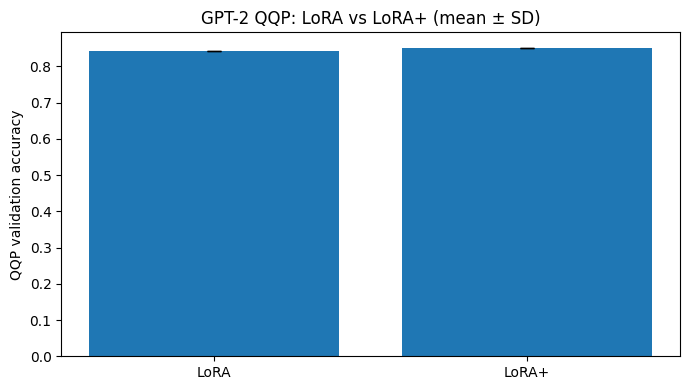

In [71]:
final=read_results('final')
if final.empty:
    print('No final results yet. Complete section 9 first.')
else:
    display(final[['method','seed','lr_A','lr_B','ratio','accuracy','f1',
                   'train_runtime_seconds','peak_gpu_memory_gb','trainable_parameters']]
            .sort_values(['method','seed']))
    summary=final.groupby('method').agg(
        n=('accuracy','size'), accuracy_mean=('accuracy','mean'),
        accuracy_std=('accuracy','std'), f1_mean=('f1','mean'),f1_std=('f1','std'),
        runtime_mean_sec=('train_runtime_seconds','mean'),
        peak_memory_mean_gb=('peak_gpu_memory_gb','mean'),
        trainable_parameters=('trainable_parameters','first')).reset_index()
    display(summary)
    summary.to_csv(ROOT/'final_summary.csv',index=False)
    final.to_csv(ROOT/'final_results.csv',index=False)
    if set(final.method)=={'LoRA','LoRA+'}:
        fig,ax=plt.subplots(figsize=(7,4))
        ax.bar(summary['method'],summary['accuracy_mean'],yerr=summary['accuracy_std'].fillna(0),capsize=5)
        ax.set_ylabel('QQP validation accuracy');ax.set_title('GPT-2 QQP: LoRA vs LoRA+ (mean ± SD)')
        fig.tight_layout();fig.savefig(ROOT/'accuracy_comparison.png',dpi=180);plt.show()

In [72]:

from pathlib import Path
import json
import pandas as pd

screen = read_results('screening')
final = read_results('final')

assert len(screen) == 9, f"Expected 9 screening runs, got {len(screen)}"
assert len(final) == 6, f"Expected 6 final runs, got {len(final)}"
assert screen['run_id'].is_unique
assert final['run_id'].is_unique

for method, expected_lr, expected_ratio in [
    ('LoRA', 0.0004, 1),
    ('LoRA+', 0.0002, 16),
]:
    rows = final[final['method'] == method]
    assert sorted(rows['seed'].astype(int)) == [42, 43, 44]
    assert (rows['global_steps'] == 4689).all()
    assert (rows['train_samples'] == 50000).all()
    assert (rows['validation_samples'] == 40430).all()
    assert (rows['epochs'] == 3).all()
    assert (rows['subset_sha256'] == subset_digest).all()
    assert (rows['lr_A'].round(7) == expected_lr).all()
    assert (rows['ratio'] == expected_ratio).all()

all_runs = list((ROOT / 'screening').glob('*/result.json'))
all_runs += list((ROOT / 'final').glob('*/result.json'))

missing_logs = [
    str(p.parent) for p in all_runs
    if not (p.parent / 'trainer_log_history.json').exists()
]

print('Screening:', len(screen), '/ 9; final:', len(final), '/ 6')
print('Missing training histories:', len(missing_logs))
for item in missing_logs:
    print(' ', item)

assert not missing_logs, 'Some history files are missing; inspect paths.'
print('PASS: final seeds, steps, dataset and settings verified.')


Screening: 9 / 9; final: 6 / 6
Missing training histories: 0
PASS: final seeds, steps, dataset and settings verified.


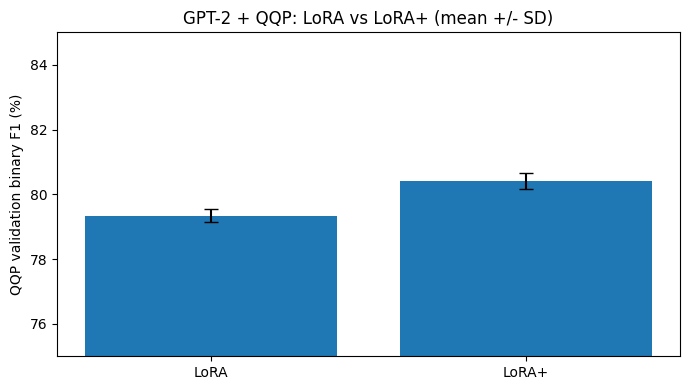

Saved: /content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k/f1_comparison.png


In [73]:

import matplotlib.pyplot as plt

final = read_results('final')

summary_f1 = final.groupby('method').agg(
    f1_mean=('f1', 'mean'),
    f1_std=('f1', 'std'),
    n=('f1', 'size'),
).reindex(['LoRA', 'LoRA+'])

assert summary_f1['n'].tolist() == [3, 3]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    summary_f1.index,
    100 * summary_f1['f1_mean'],
    yerr=100 * summary_f1['f1_std'],
    capsize=5
)

ax.set_ylabel('QQP validation binary F1 (%)')
ax.set_title('GPT-2 + QQP: LoRA vs LoRA+ (mean +/- SD)')
ax.set_ylim(75, 85)

fig.tight_layout()
fig.savefig(ROOT / 'f1_comparison.png', dpi=180)
plt.show()

print('Saved:', ROOT / 'f1_comparison.png')


## 11. Plot training convergence (loss vs global step)

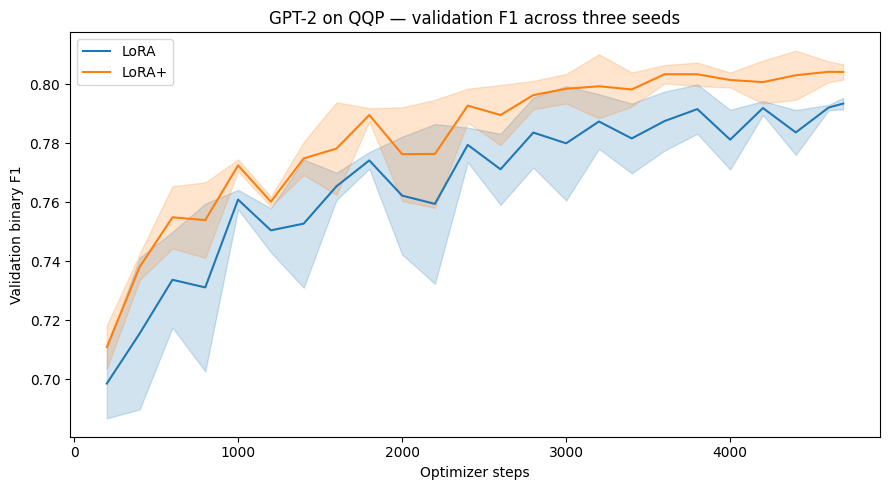

Saved: /content/drive/MyDrive/LoRA_Project/Asneem_GPT2_QQP_50k/convergence.png


In [74]:
import json
import pandas as pd
import matplotlib.pyplot as plt

winners = json.loads((ROOT / "selected_winners.json").read_text())
fig, ax = plt.subplots(figsize=(9, 5))

for winner in winners:
    method = winner["method"]
    lr_a = float(winner["lr_A"])
    ratio = int(winner["ratio"])
    curves = []

    for seed in (42, 43, 44):
        run_id = f"final_A{lr_a:.0e}_ratio{ratio}_seed{seed}"
        log_path = ROOT / "final" / run_id / "trainer_log_history.json"
        entries = json.loads(log_path.read_text())

        # Keep the last recorded validation score if a step appears twice.
        scores = {
            entry["step"]: entry["eval_f1"]
            for entry in entries
            if "step" in entry and "eval_f1" in entry
        }
        if not scores:
            raise ValueError(f"No validation F1 scores in {log_path}")

        curves.append(pd.Series(scores, name=seed, dtype=float))

    # Compare only optimizer steps that all three seeds recorded.
    f1_by_step = pd.concat(curves, axis=1, join="inner").sort_index()
    if f1_by_step.empty:
        raise ValueError(f"No shared evaluation steps for {method}")

    steps = f1_by_step.index.to_numpy()
    mean = f1_by_step.mean(axis=1).to_numpy()
    std = f1_by_step.std(axis=1).to_numpy()

    line, = ax.plot(steps, mean, label=method)
    ax.fill_between(
        steps, mean - std, mean + std, color=line.get_color(), alpha=0.2
    )

ax.set(
    xlabel="Optimizer steps",
    ylabel="Validation binary F1",
    title="GPT-2 on QQP - validation F1 across three seeds",
)
ax.legend()
fig.tight_layout()

output_path = ROOT / "convergence.png"
fig.savefig(output_path, dpi=180)
plt.show()
print("Saved:", output_path)

## 12. Download the experiment results as zip


In [76]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

root = Path(ROOT)
convergence_path = root / "convergence.png"

if not convergence_path.is_file():
    raise FileNotFoundError("Run the convergence plot cell before exporting.")

zip_path = Path("/content/gpt2_qqp_lightweight_results.zip")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as archive:
    for path in sorted(root.rglob("*")):
        relative_path = path.relative_to(root)

        if not path.is_file():
            continue
        if any(
            part in {"adapter", "checkpoints"} or part.startswith("checkpoint-")
            for part in relative_path.parts
        ):
            continue
        if path.suffix.lower() in {".json", ".csv", ".png", ".txt"}:
            archive.write(path, arcname=relative_path)

print("Backup created:", zip_path)
print(f"Size: {zip_path.stat().st_size / 1024**2:.2f} MB")
files.download(str(zip_path))

Backup created: /content/gpt2_qqp_lightweight_results.zip
Size: 0.27 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Disconnect Colab GPU

In [77]:
# Run ONLY after every JSON and the CSV are downloaded.
from google.colab import runtime
runtime.unassign()

## 14 .GitHub Integration - Save Completed Experiment

This section versions the completed GPT-2 + QQP notebook
in the shared LoRA-Plus repository.

All training results remain stored in Google Drive.
No experiments are rerun during GitHub synchronization.

In [21]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")

notebooks = list(drive_root.rglob("GPT2_QQP*.ipynb"))

for i, notebook in enumerate(notebooks, 1):
    print(f"{i}. {notebook}")

if not notebooks:
    print("No matching notebook found in this mounted Google Drive.")

1. /content/drive/MyDrive/Colab Notebooks/GPT2_QQP_.ipynb


In [22]:
from pathlib import Path
import subprocess
import shutil

PROJECT_DIR = Path("/content/LoRA-Plus")

# Update this path to your actual saved notebook location
NOTEBOOK_SOURCE = Path(
    "/content/drive/MyDrive/Colab Notebooks/GPT2_QQP_.ipynb"
)

NOTEBOOK_DEST = PROJECT_DIR / "notebooks" / "GPT2_QQP.ipynb"

assert (PROJECT_DIR / ".git").exists(), "Run the GitHub clone cell first."
assert NOTEBOOK_SOURCE.exists(), (
    f"Notebook not found: {NOTEBOOK_SOURCE}"
)

NOTEBOOK_DEST.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(NOTEBOOK_SOURCE, NOTEBOOK_DEST)

subprocess.run(
    ["git", "-C", str(PROJECT_DIR), "status", "--short"],
    check=True
)

print("Notebook copied into GitHub repository.")


Notebook copied into GitHub repository.


In [23]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"

subprocess.run(
    ["git", "-C", PROJECT_DIR, "config", "user.name", "Asneem Athar Shaik"],
    check=True
)

subprocess.run(
    ["git", "-C", PROJECT_DIR, "config", "user.email", "atharasneemsjsu@gmail.com"],
    check=True
)

# Stage only your GPT-2 QQP notebook
subprocess.run(
    ["git", "-C", PROJECT_DIR, "add", "notebooks/GPT2_QQP.ipynb"],
    check=True
)

# Verify staged changes
subprocess.run(
    ["git", "-C", PROJECT_DIR, "diff", "--cached", "--stat"],
    check=True
)

print("Notebook staged successfully!")

Notebook staged successfully!


In [24]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"
NOTEBOOK = "notebooks/GPT2_QQP.ipynb"

def git(*args):
    return subprocess.run(
        ["git", "-C", PROJECT_DIR, *args],
        check=True,
        text=True,
        capture_output=True
    )

# Switch to main
git("switch", "main")

# Stage only your notebook
git("add", NOTEBOOK)

staged = git("diff", "--cached", "--name-only").stdout.splitlines()
assert staged == [NOTEBOOK], f"Unexpected staged files: {staged}"

# Commit
result = git(
    "commit",
    "-m",
    "Update GPT-2 QQP LoRA and LoRA+ experiments"
)

print(result.stdout)
print("Committed to branch:", git("branch", "--show-current").stdout.strip())

[main 278ec37] Update GPT-2 QQP LoRA and LoRA+ experiments
 1 file changed, 1 insertion(+), 9042 deletions(-)

Committed to branch: main


In [25]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"

subprocess.run(
    ["git", "-C", PROJECT_DIR, "fetch", "origin", "main"],
    check=True
)

subprocess.run(
    ["git", "-C", PROJECT_DIR, "status", "-sb"],
    check=True
)

subprocess.run(
    ["git", "-C", PROJECT_DIR, "log", "-1", "--oneline"],
    check=True
)

CompletedProcess(args=['git', '-C', '/content/LoRA-Plus', 'log', '-1', '--oneline'], returncode=0)

In [26]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"

def git(*args):
    result = subprocess.run(
        ["git", "-C", PROJECT_DIR, *args],
        text=True,
        capture_output=True,
        check=True
    )
    return result.stdout.strip()

print("Branch:", git("branch", "--show-current"))
print("Status:", git("status", "-sb"))
print("Local commit:", git("rev-parse", "--short", "HEAD"))
print("Remote commit:", git("rev-parse", "--short", "origin/main"))

print("\nCommits not yet on GitHub:")
print(git("log", "--oneline", "origin/main..HEAD"))

print("\nNew commits from teammates:")
print(git("log", "--oneline", "HEAD..origin/main"))

Branch: main
Status: ## main...origin/main [ahead 1]
Local commit: 278ec37
Remote commit: cc31192

Commits not yet on GitHub:
278ec37 Update GPT-2 QQP LoRA and LoRA+ experiments

New commits from teammates:



In [29]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"

def git(*args):
    r = subprocess.run(
        ["git", "-C", PROJECT_DIR, *args],
        capture_output=True,
        text=True
    )
    print(r.stdout or r.stderr)
    return r

git("fetch", "origin", "main")
git("status", "-sb")
git("log", "--oneline", "-3", "origin/main")

From https://github.com/Ramprasath-Meganathan/LoRA-Plus
 * branch            main       -> FETCH_HEAD

## main...origin/main [ahead 1]

cc31192 made notebooks consistent
a8a3406 updated Readme file as per the repo changes
e5bb133 uploaded final results of all roberta model experiments



CompletedProcess(args=['git', '-C', '/content/LoRA-Plus', 'log', '--oneline', '-3', 'origin/main'], returncode=0, stdout='cc31192 made notebooks consistent\na8a3406 updated Readme file as per the repo changes\ne5bb133 uploaded final results of all roberta model experiments\n', stderr='')

In [31]:
import subprocess

PROJECT_DIR = "/content/LoRA-Plus"

def check(*args):
    result = subprocess.run(
        ["git", "-C", PROJECT_DIR, *args],
        capture_output=True,
        text=True
    )
    print(result.stdout or result.stderr)

print("CURRENT BRANCH:")
check("branch", "--show-current")

print("\nCURRENT COMMIT:")
check("log", "-1", "--oneline")

print("\nCOMMITS NOT ON GITHUB:")
check("log", "--oneline", "origin/main..HEAD")

print("\nWORKING TREE STATUS:")
check("status", "-sb")

print("\nFILES CHANGED IN LOCAL COMMITS:")
check("diff", "--stat", "origin/main..HEAD")

CURRENT BRANCH:
main


CURRENT COMMIT:
278ec37 Update GPT-2 QQP LoRA and LoRA+ experiments


COMMITS NOT ON GITHUB:
278ec37 Update GPT-2 QQP LoRA and LoRA+ experiments


WORKING TREE STATUS:
## main...origin/main [ahead 1]


FILES CHANGED IN LOCAL COMMITS:
 notebooks/GPT2_QQP.ipynb | 9043 +---------------------------------------------
 1 file changed, 1 insertion(+), 9042 deletions(-)



In [32]:
from pathlib import Path
import subprocess
import shutil

PROJECT_DIR = Path("/content/LoRA-Plus")
SOURCE = Path("/content/drive/MyDrive/Colab Notebooks/GPT2_QQP_.ipynb")
DEST = PROJECT_DIR / "notebooks" / "GPT2_QQP_Asneem_Final.ipynb"

def git(*args):
    return subprocess.run(
        ["git", "-C", str(PROJECT_DIR), *args],
        check=True, text=True, capture_output=True
    ).stdout.strip()

# Ensure the final notebook exists
assert SOURCE.exists(), f"Notebook not found: {SOURCE}"
assert (PROJECT_DIR / ".git").exists()
assert git("branch", "--show-current") == "main"

# Ensure no uncommitted changes would be lost
assert not git("status", "--porcelain"), "Uncommitted changes found; stop."

# Confirm that only your earlier commit is ahead
assert git("rev-list", "--count", "origin/main..HEAD") == "1"
assert git("rev-parse", "--short", "HEAD") == "26c2726"

# Preserve your earlier commit in a backup branch
git("branch", "backup/asneem-original-commit")

# Move main to Ram's latest commit
git("reset", "--hard", "origin/main")

# Add your final notebook without replacing Ram's
assert not DEST.exists(), "Destination already exists; stop."
shutil.copy2(SOURCE, DEST)

print("Final notebook copied:", DEST)
print("Current branch:", git("branch", "--show-current"))
print("Status:", git("status", "--short"))

AssertionError: 

In [28]:
from google.colab import userdata
from pathlib import Path
import subprocess
import tempfile
import os

PROJECT_DIR = "/content/LoRA-Plus"
token = userdata.get("GITHUB_TOKEN")

assert token, "GITHUB_TOKEN is missing from Colab Secrets."

with tempfile.TemporaryDirectory() as tmp:
    askpass = Path(tmp) / "askpass.sh"
    askpass.write_text(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  *Username*) echo "x-access-token" ;;\n'
        '  *Password*) printf "%s" "$GITHUB_TOKEN" ;;\n'
        'esac\n'
    )
    askpass.chmod(0o700)

    env = os.environ.copy()
    env["GIT_ASKPASS"] = str(askpass)
    env["GIT_TERMINAL_PROMPT"] = "0"
    env["GITHUB_TOKEN"] = token

    result = subprocess.run(
        ["git", "-C", PROJECT_DIR, "push", "origin", "main"],
        env=env,
        capture_output=True,
        text=True
    )

print("Exit code:", result.returncode)
print(result.stderr)

if result.returncode == 0:
    print("Successfully pushed to GitHub main!")
else:
    print("Push failed. See the error above.")

Exit code: 128
remote: Permission to Ramprasath-Meganathan/LoRA-Plus.git denied to asneem1234.
fatal: unable to access 'https://github.com/Ramprasath-Meganathan/LoRA-Plus.git/': The requested URL returned error: 403

Push failed. See the error above.
